Assigned labels per cluster: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9)]
Unique labels used: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9)]
Accuracy: 0.7061769616026711
Confusion matrix:
 [[177   0   0   0   1   0   0   0   0   0]
 [  0  55  25   0   0   0   2   0  99   1]
 [  1   2 151  12   0   0   0   3   8   0]
 [  0   0   1 163   0   3   0   6   8   2]
 [  0   5   0   0 164   0   0   8   3   1]
 [  0   0   0   5   1 103   1   0   0  72]
 [  1   1   0   0   0   0 177   0   2   0]
 [  0   2   0   0   0   0   0 175   2   0]
 [  1   6   4  48   0   1   2   6 100   6]
 [  0  21   0 144   0   1   0   8   2   4]]


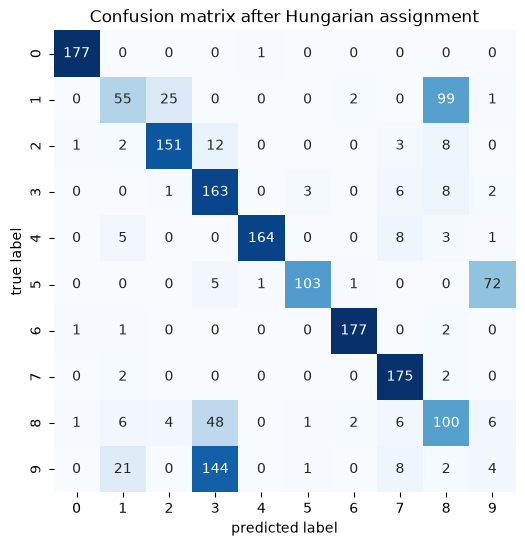

In [1]:
import numpy as np
from sklearn.datasets import load_digits
from sklearn.cluster import KMeans
from scipy.optimize import linear_sum_assignment
from sklearn.metrics import confusion_matrix, accuracy_score
import matplotlib.pyplot as plt
import seaborn as sns

# ------------------------------------------------------------------
# 1. Load data and cluster
# ------------------------------------------------------------------
digits = load_digits()
kmeans = KMeans(n_clusters=10, random_state=0)
clusters = kmeans.fit_predict(digits.data)

# ------------------------------------------------------------------
# 2. Build the cluster x true-label count matrix
#    counts[c, t] = number of samples in cluster c whose true label is t
# ------------------------------------------------------------------
n_clusters = 10
n_classes = 10
counts = np.zeros((n_clusters, n_classes), dtype=int)
for c in range(n_clusters):
    mask = (clusters == c)
    for t in range(n_classes):
        counts[c, t] = np.sum(digits.target[mask] == t)

# ------------------------------------------------------------------
# 3. Optimal one-to-one assignment (Hungarian algorithm).
#    Negate counts because linear_sum_assignment minimizes.
#    Each row (cluster) is matched to exactly one column (label),
#    and each label is used at most once -> a perfect permutation.
# ------------------------------------------------------------------
row_ind, col_ind = linear_sum_assignment(-counts)

# Build the cluster -> label mapping
cluster_to_label = dict(zip(row_ind, col_ind))

# Apply the mapping to every sample
labels = np.array([cluster_to_label[c] for c in clusters])

# ------------------------------------------------------------------
# 4. Sanity check: each digit 0..9 appears exactly once as a cluster label
# ------------------------------------------------------------------
print("Assigned labels per cluster:",
      sorted(cluster_to_label.values()))
print("Unique labels used:", sorted(set(labels)))

# ------------------------------------------------------------------
# 5. Evaluation
# ------------------------------------------------------------------
print("Accuracy:", accuracy_score(digits.target, labels))

mat = confusion_matrix(digits.target, labels)
print("Confusion matrix:\n", mat)

# Visualize (with rows = true label, columns = predicted label)
plt.figure(figsize=(8, 6))
sns.heatmap(mat, square=True, annot=True, fmt='d',
            cbar=False, cmap='Blues',
            xticklabels=digits.target_names,
            yticklabels=digits.target_names)
plt.xlabel('predicted label')
plt.ylabel('true label')
plt.title('Confusion matrix after Hungarian assignment')
plt.show()

In [2]:
from scipy.stats import mode

# Method 1: mode (per-cluster majority) — Purity-maximizing, not injective
labels_mode = np.zeros_like(clusters)
for c in range(n_clusters):
    labels_mode[clusters == c] = mode(digits.target[clusters == c])[0]

# Method 2: Hungarian (already computed above)
print("Method 1 (mode):")
print("  Purity  :", np.sum(counts.max(axis=1)) / len(clusters))
print("  Accuracy:", accuracy_score(digits.target, labels_mode))
print("  Labels used:", sorted(set(labels_mode)))

print("\nMethod 2 (Hungarian):")
print("  Purity  :", np.sum(counts.max(axis=1)) / len(clusters))
print("  Accuracy:", accuracy_score(digits.target, labels))
print("  Labels used:", sorted(set(labels)))

Method 1 (mode):
  Purity  : 0.7440178074568725
  Accuracy: 0.7440178074568725
  Labels used: [np.int32(0), np.int32(1), np.int32(2), np.int32(3), np.int32(4), np.int32(5), np.int32(6), np.int32(7), np.int32(8)]

Method 2 (Hungarian):
  Purity  : 0.7440178074568725
  Accuracy: 0.7061769616026711
  Labels used: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9)]
